In [1]:
import sys

print("Python Version:")
print(sys.version)

print("\nPython Location:")
print(sys.executable)

Python Version:
3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]

Python Location:
c:\Users\DHARANI S\Desktop\Ecommerce_Customer_Segmentation\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import streamlit as st
import joblib

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nAll libraries imported successfully!")

Pandas: 3.1.1
NumPy: 2.5.4
Scikit-learn: 1.9.1

All libraries imported successfully!


In [3]:
import pandas as pd
import numpy as np

print("Pandas imported successfully!")
print("NumPy imported successfully!")

Pandas imported successfully!
NumPy imported successfully!


In [4]:
# Load the Online Retail dataset

file_path = "../data/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
# Display first five rows

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
print("Dataset Shape:", df.shape)

Dataset Shape: (541909, 8)


In [7]:
print("Column Names:")

print(df.columns.tolist())

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [8]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [9]:

df.describe()


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [10]:

df.tail()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [11]:
# Check missing values in each column

print("Missing Values in Each Column:")

print(df.isnull().sum())

Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [12]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 5268


In [13]:
# Check negative quantities

negative_quantity = (df["Quantity"] < 0).sum()

print("Negative Quantity Records:", negative_quantity)

Negative Quantity Records: 10624


In [14]:
# Check invalid prices

invalid_prices = (df["UnitPrice"] <= 0).sum()

print("Invalid Price Records:", invalid_prices)

Invalid Price Records: 2517


In [15]:
# Check cancelled invoices

cancelled_invoices = df["InvoiceNo"].astype(str).str.startswith("C").sum()

print("Cancelled Invoice Records:", cancelled_invoices)

Cancelled Invoice Records: 9288


In [16]:
# Remove duplicate records

df = df.drop_duplicates()

print("Duplicate records removed successfully!")

print("Updated Dataset Shape:", df.shape)

Duplicate records removed successfully!
Updated Dataset Shape: (536641, 8)


In [17]:
# Verify duplicate removal

print("Remaining Duplicates:", df.duplicated().sum())

Remaining Duplicates: 0


In [18]:
print("Missing CustomerID:", df["CustomerID"].isnull().sum())

Missing CustomerID: 135037


In [19]:
# Remove records with missing CustomerID

df = df.dropna(subset=["CustomerID"])

print("Missing CustomerID records removed!")

print("Remaining Missing CustomerID:", df["CustomerID"].isnull().sum())

Missing CustomerID records removed!
Remaining Missing CustomerID: 0


In [20]:
# Remove cancelled invoices

df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

print("Cancelled invoices removed!")
print("Updated Dataset Shape:", df.shape)

Cancelled invoices removed!
Updated Dataset Shape: (392732, 8)


In [21]:
# Keep only positive quantities

df = df[df["Quantity"] > 0]

print("Invalid quantities removed!")

Invalid quantities removed!


In [22]:
# Keep only positive prices

df = df[df["UnitPrice"] > 0]

print("Invalid prices removed!")

Invalid prices removed!


In [23]:
# Calculate total transaction amount

df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print("TotalAmount column created successfully!")

df[["Quantity", "UnitPrice", "TotalAmount"]].head()

TotalAmount column created successfully!


,Quantity,UnitPrice,TotalAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [24]:
# Convert CustomerID into integer format

df["CustomerID"] = df["CustomerID"].astype(int)

print("CustomerID converted successfully!")

print(df["CustomerID"].dtype)

CustomerID converted successfully!
int64


In [25]:
# Final dataset verification

print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Final Dataset Shape: (392692, 9)

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64

Duplicate Records: 0

Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              int64
Country                   str
TotalAmount           float64
dtype: object


In [26]:
# Save cleaned dataset

df.to_csv("../data/cleaned_online_retail.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("RFM libraries imported successfully!")

RFM libraries imported successfully!


In [28]:
# Check invoice date data type

print("InvoiceDate Data Type:")
print(df["InvoiceDate"].dtype)

# Display sample invoice dates
print("\nSample Invoice Dates:")
print(df["InvoiceDate"].head())

InvoiceDate Data Type:
datetime64[us]

Sample Invoice Dates:
0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[us]


In [29]:
# Convert InvoiceDate into datetime format

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("InvoiceDate converted successfully!")

print(df["InvoiceDate"].dtype)

InvoiceDate converted successfully!
datetime64[us]


In [30]:
# Find the latest invoice date

latest_date = df["InvoiceDate"].max()

# Set reference date one day after latest purchase
reference_date = latest_date + pd.Timedelta(days=1)

print("Latest Invoice Date:", latest_date)
print("Reference Date:", reference_date)

Latest Invoice Date: 2011-12-09 12:50:00
Reference Date: 2011-12-10 12:50:00


In [31]:
# Calculate Recency for each customer

recency = df.groupby("CustomerID").agg(
    LastPurchaseDate=("InvoiceDate", "max")
)

recency["Recency"] = (
    reference_date - recency["LastPurchaseDate"]
).dt.days

print("Recency calculated successfully!")

recency.head()

Recency calculated successfully!


,LastPurchaseDate,Recency
CustomerID,,
12346,2011-01-18 10:01:00,326
12347,2011-12-07 15:52:00,2
12348,2011-09-25 13:13:00,75
12349,2011-11-21 09:51:00,19
12350,2011-02-02 16:01:00,310


In [32]:
# Calculate Frequency

frequency = df.groupby("CustomerID").agg(
    Frequency=("InvoiceNo", "nunique")
)

print("Frequency calculated successfully!")

frequency.head()

Frequency calculated successfully!


,Frequency
CustomerID,
12346,1
12347,7
12348,4
12349,1
12350,1


In [33]:
# Calculate Monetary value

monetary = df.groupby("CustomerID").agg(
    Monetary=("TotalAmount", "sum")
)

print("Monetary calculated successfully!")

monetary.head()

Monetary calculated successfully!


,Monetary
CustomerID,
12346,77183.60
12347,4310.00
12348,1797.24
12349,1757.55
12350,334.40


In [34]:
# Combine RFM features

rfm = recency[["Recency"]].join(frequency).join(monetary)

print("RFM dataset created successfully!")

rfm.head()

RFM dataset created successfully!


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [35]:
# Statistical summary of RFM

rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [36]:
# Check RFM dataset information

print("RFM Dataset Shape:", rfm.shape)

print("\nMissing Values:")
print(rfm.isnull().sum())

RFM Dataset Shape: (4338, 3)

Missing Values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


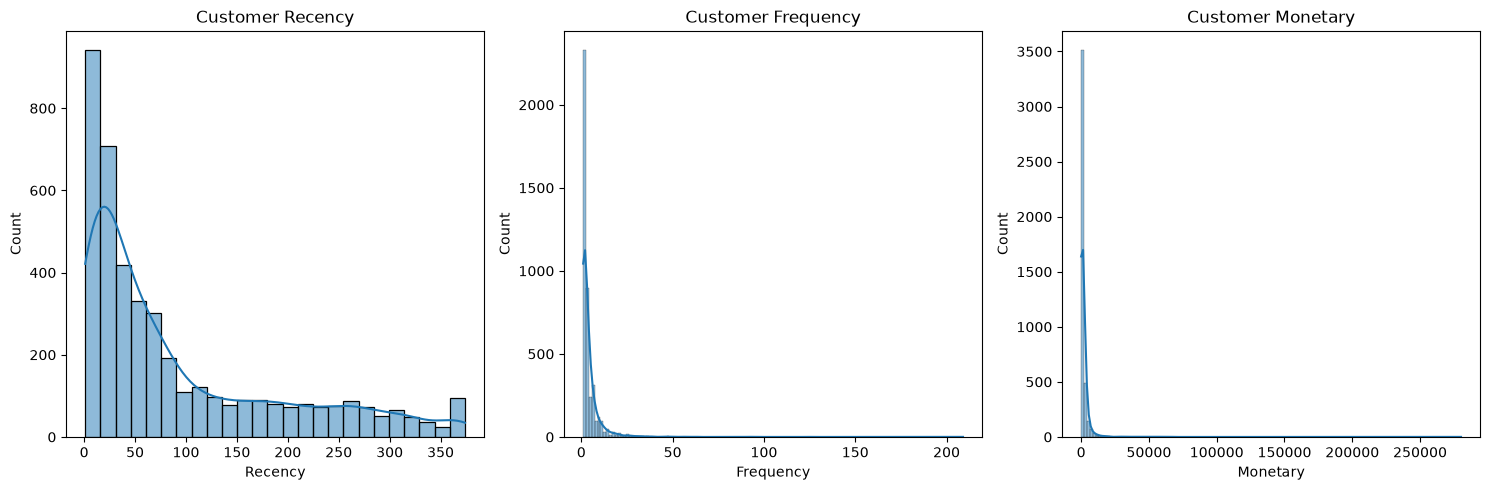

In [37]:
# Plot RFM distributions

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(rfm["Recency"], kde=True)
plt.title("Customer Recency")

plt.subplot(1, 3, 2)
sns.histplot(rfm["Frequency"], kde=True)
plt.title("Customer Frequency")

plt.subplot(1, 3, 3)
sns.histplot(rfm["Monetary"], kde=True)
plt.title("Customer Monetary")

plt.tight_layout()
plt.show()

In [38]:
# Save RFM customer data

rfm.to_csv("../outputs/customer_rfm.csv")

print("RFM dataset saved successfully!")

RFM dataset saved successfully!


In [39]:
from sklearn.preprocessing import StandardScaler

print("StandardScaler imported successfully!")

StandardScaler imported successfully!


In [40]:
# Display RFM data

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [41]:
# Check minimum and maximum values

print(rfm.min())
print("\n")
print(rfm.max())

Recency      1.00
Frequency    1.00
Monetary     3.75
dtype: float64


Recency         374.00
Frequency       209.00
Monetary     280206.02
dtype: float64


In [42]:
# Initialize StandardScaler

scaler = StandardScaler()

# Scale RFM features

rfm_scaled = scaler.fit_transform(rfm)

print("RFM features scaled successfully!")

RFM features scaled successfully!


In [43]:
# Convert scaled data into DataFrame

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

print("Scaled RFM Dataset:")

rfm_scaled.head()

Scaled RFM Dataset:


,Recency,Frequency,Monetary
CustomerID,,,
12346,2.334574,-0.425097,8.363010
12347,-0.905340,0.354417,0.251699
12348,-0.175360,-0.035340,-0.027988
12349,-0.735345,-0.425097,-0.032406
12350,2.174578,-0.425097,-0.190812


In [44]:
# Check scaled feature statistics

rfm_scaled.describe()

,Recency,Frequency,Monetary
count,4.338000e+03,4.338000e+03,4.338000e+03
mean,2.702618e-17,1.801745e-17,2.293130e-17
std,1.000115e+00,1.000115e+00,1.000115e+00
min,-9.153401e-01,-4.250965e-01,-2.276151e-01
25%,-7.453445e-01,-4.250965e-01,-1.939190e-01
50%,-4.153533e-01,-2.951776e-01,-1.536162e-01
75%,4.946227e-01,9.457903e-02,-4.319704e-02
max,2.814561e+00,2.659803e+01,3.096074e+01


In [45]:
from sklearn.cluster import KMeans

print("KMeans imported successfully!")

KMeans imported successfully!


In [46]:

# Calculate WCSS for different cluster numbers

wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    wcss.append(kmeans.inertia_)

print("WCSS values:")
print(wcss)

WCSS values:
[13013.999999999996, 9014.566279572977, 5441.3235868296615, 4096.300210662248, 3119.7898598001484, 2473.79336356476, 2023.586627223549, 1717.011043083917, 1468.787102184297, 1281.048051101327]


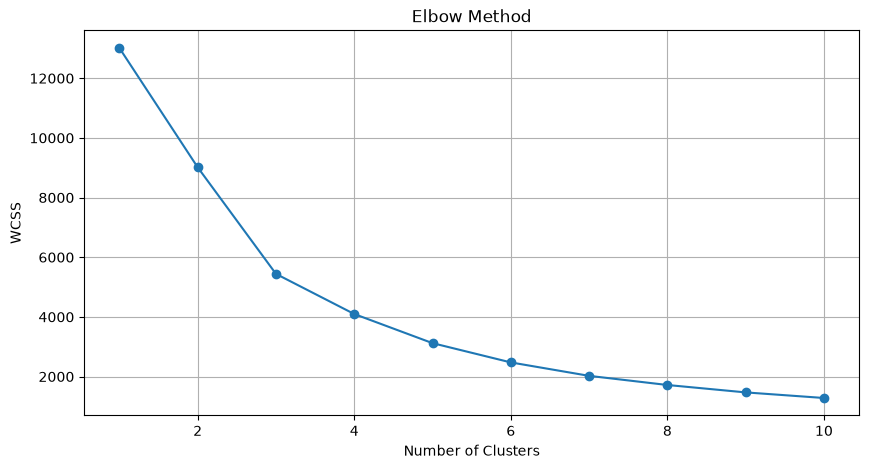

In [47]:
# Plot Elbow Method

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid(True)

plt.show()

In [48]:
from sklearn.metrics import silhouette_score

print("Silhouette Score imported successfully!")

Silhouette Score imported successfully!


In [49]:
# Evaluate different cluster numbers

silhouette_scores = []

for i in range(2, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    silhouette_scores.append(score)

    print("Clusters:", i, "| Score:", round(score, 4))

Clusters: 2 | Score: 0.8958
Clusters: 3 | Score: 0.5942
Clusters: 4 | Score: 0.6162
Clusters: 5 | Score: 0.6165
Clusters: 6 | Score: 0.5983
Clusters: 7 | Score: 0.5165
Clusters: 8 | Score: 0.4859
Clusters: 9 | Score: 0.4784
Clusters: 10 | Score: 0.4792


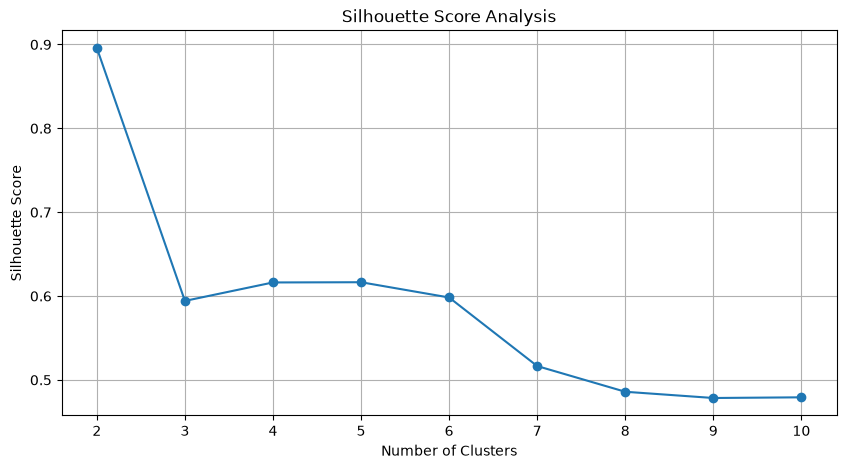

In [50]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.grid(True)

plt.show()

In [51]:
# Train K-Means model

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans.fit(rfm_scaled)

print("K-Means model trained successfully!")

K-Means model trained successfully!


In [52]:
# Assign cluster labels

rfm["Cluster"] = kmeans.labels_

print("Customer clusters assigned successfully!")

rfm.head()

Customer clusters assigned successfully!


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,3
12347,2,7,4310.00,0
12348,75,4,1797.24,0
12349,19,1,1757.55,0
12350,310,1,334.40,1


In [53]:
# Count customers per cluster

print(rfm["Cluster"].value_counts().sort_index())

Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64


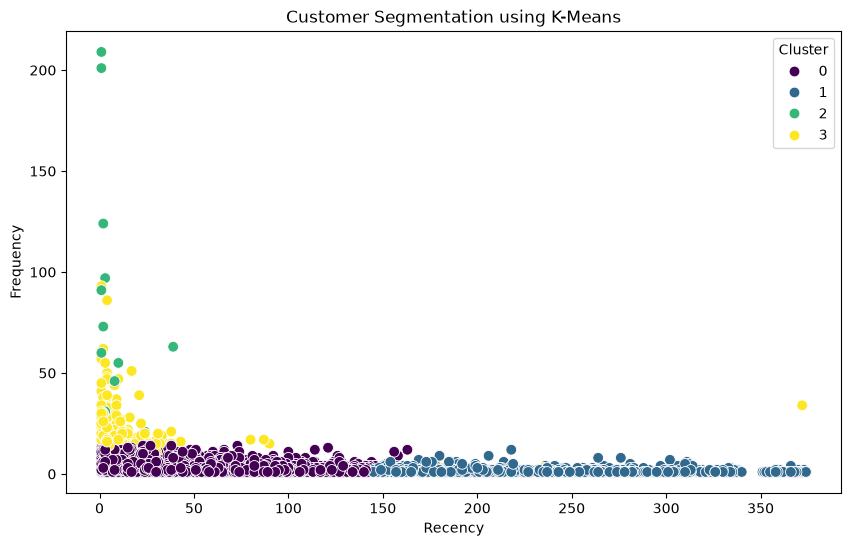

In [54]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Frequency",
    hue="Cluster",
    palette="viridis",
    s=60
)

plt.title("Customer Segmentation using K-Means")
plt.show()

In [55]:
# Save customer segmentation results

rfm.to_csv(
    "../outputs/customer_segments.csv"
)

print("Customer segmentation results saved successfully!")

Customer segmentation results saved successfully!


In [56]:
# Calculate average RFM values for each cluster

cluster_analysis = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

print("Customer Cluster Analysis:")

cluster_analysis

Customer Cluster Analysis:


,Recency,Frequency,Monetary
Cluster,,,
0,43.70,3.68,1353.63
1,248.08,1.55,478.85
2,7.38,82.54,127187.96
3,15.50,22.33,12690.50


In [57]:
# Count customers in each cluster

cluster_counts = rfm["Cluster"].value_counts().sort_index()

print("Customers in Each Cluster:")

print(cluster_counts)

Customers in Each Cluster:
Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64


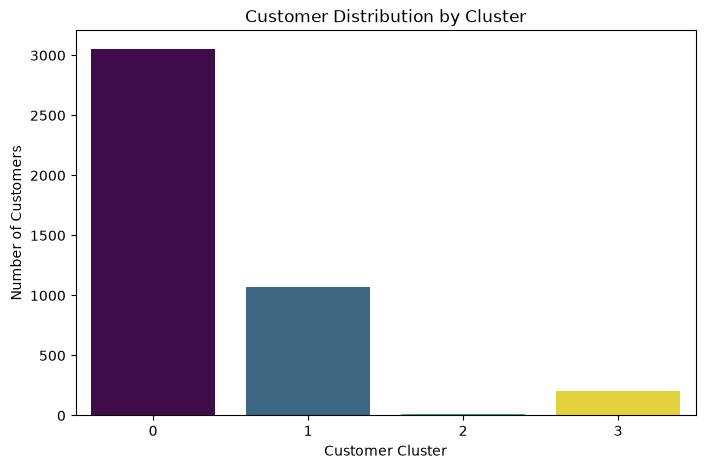

In [58]:
# Customer distribution visualization

plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="Cluster",
    hue="Cluster",
    palette="viridis",
    legend=False
)

plt.title("Customer Distribution by Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")

plt.show()

In [59]:
# Display cluster analysis

print(cluster_analysis)

         Recency  Frequency   Monetary
Cluster                               
0          43.70       3.68    1353.63
1         248.08       1.55     478.85
2           7.38      82.54  127187.96
3          15.50      22.33   12690.50


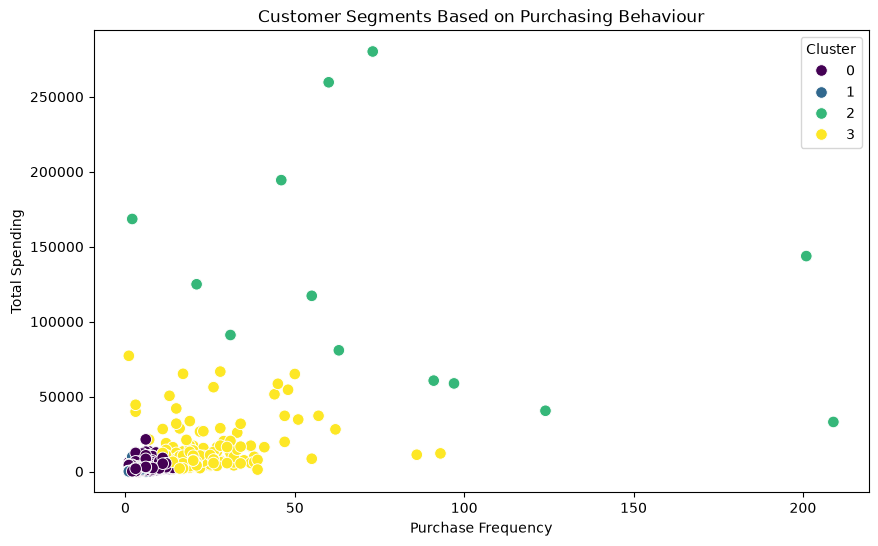

In [60]:
# Visualize customer segments

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    s=70
)

plt.title("Customer Segments Based on Purchasing Behaviour")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending")

plt.show()

In [61]:
from sklearn.metrics.pairwise import cosine_similarity

print("Cosine Similarity imported successfully!")

Cosine Similarity imported successfully!


In [62]:
# Create customer-product purchase matrix

product_matrix = df.pivot_table(
    index="CustomerID",
    columns="StockCode",
    values="Quantity",
    aggfunc="sum",
    fill_value=0
)

print("Product Purchase Matrix Created!")

print("Matrix Shape:", product_matrix.shape)

Product Purchase Matrix Created!
Matrix Shape: (4338, 3665)


In [63]:
# Calculate product similarity

product_similarity = cosine_similarity(
    product_matrix.T
)

print("Product Similarity Calculated!")

print("Similarity Matrix Shape:", product_similarity.shape)

Product Similarity Calculated!
Similarity Matrix Shape: (3665, 3665)


In [64]:
# Create recommendation function

product_codes = product_matrix.columns.tolist()

def recommend_products(product_code, top_n=5):

    if product_code not in product_codes:
        return "Product not found!"

    product_index = product_codes.index(product_code)

    similarity_scores = product_similarity[product_index]

    similar_products = sorted(
        enumerate(similarity_scores),
        key=lambda x: x[1],
        reverse=True
    )

    recommendations = []

    for index, score in similar_products:

        if index != product_index:

            recommendations.append({
                "StockCode": product_codes[index],
                "Similarity": round(float(score), 4)
            })

        if len(recommendations) == top_n:
            break

    return pd.DataFrame(recommendations)

print("Recommendation function created successfully!")

Recommendation function created successfully!


In [65]:
# Select a product for testing

sample_product = product_codes[0]

print("Selected Product:", sample_product)

recommend_products(sample_product)

Selected Product: 10002


,StockCode,Similarity
0,10125,0.8539
1,23224,0.7134
2,23222,0.6990
3,85014A,0.6262
4,20682,0.5973


In [66]:
# Save product similarity matrix

np.save(
    "../outputs/product_similarity.npy",
    product_similarity
)

print("Product similarity matrix saved successfully!")

Product similarity matrix saved successfully!


In [67]:
import joblib
import os

print("Joblib imported successfully!")

Joblib imported successfully!


In [68]:
# Save K-Means model

joblib.dump(
    kmeans,
    "../models/kmeans_model.pkl"
)

print("K-Means model saved successfully!")

K-Means model saved successfully!


In [69]:
# Save the StandardScaler

joblib.dump(
    scaler,
    "../models/scaler.pkl"
)

print("StandardScaler saved successfully!")

StandardScaler saved successfully!


In [70]:
# Save RFM data

joblib.dump(
    rfm,
    "../models/customer_rfm.pkl"
)

print("Customer RFM data saved successfully!")

Customer RFM data saved successfully!


In [71]:
# Save product matrix

joblib.dump(
    product_matrix,
    "../models/product_matrix.pkl"
)

# Save similarity matrix

joblib.dump(
    product_similarity,
    "../models/product_similarity.pkl"
)

print("Recommendation data saved successfully!")

Recommendation data saved successfully!


In [72]:
# Save product codes

joblib.dump(
    product_codes,
    "../models/product_codes.pkl"
)

print("Product codes saved successfully!")

Product codes saved successfully!


In [73]:
# Create cluster summary

cluster_summary = rfm.groupby("Cluster").agg(
    Customer_Count=("Recency", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
).round(2)

print("Customer Segment Summary:")

cluster_summary

Customer Segment Summary:


,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary
Cluster,,,,
0,3054,43.70,3.68,1353.63
1,1067,248.08,1.55,478.85
2,13,7.38,82.54,127187.96
3,204,15.50,22.33,12690.50


In [74]:
# Export cluster summary

cluster_summary.to_csv(
    "../outputs/cluster_summary.csv"
)

print("Cluster summary saved successfully!")

Cluster summary saved successfully!


In [75]:
# Create product similarity DataFrame

product_similarity_df = pd.DataFrame(
    product_similarity,
    index=product_codes,
    columns=product_codes
)

# Save similarity data

product_similarity_df.to_csv(
    "../outputs/product_similarity.csv"
)

print("Product recommendation data exported!")

Product recommendation data exported!


In [78]:

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import os

# Page configuration
st.set_page_config(
    page_title="E-Commerce Customer Analytics",
    page_icon="🛍️",
    layout="wide"
)

# Load saved models
BASE_DIR = os.path.abspath("..")
MODEL_DIR = os.path.join(BASE_DIR, "models")

@st.cache_resource
def load_models():

    kmeans = joblib.load(
        os.path.join(MODEL_DIR, "kmeans_model.pkl")
    )

    scaler = joblib.load(
        os.path.join(MODEL_DIR, "scaler.pkl")
    )

    rfm = joblib.load(
        os.path.join(MODEL_DIR, "customer_rfm.pkl")
    )

    product_matrix = joblib.load(
        os.path.join(MODEL_DIR, "product_matrix.pkl")
    )

    similarity = joblib.load(
        os.path.join(MODEL_DIR, "product_similarity.pkl")
    )

    product_codes = joblib.load(
        os.path.join(MODEL_DIR, "product_codes.pkl")
    )

    return (
        kmeans,
        scaler,
        rfm,
        product_matrix,
        similarity,
        product_codes
    )

# Application title
st.title("🛍️ E-Commerce Customer Segmentation")
st.subheader("Customer Analytics & Product Recommendation System")

# Load models
try:
    kmeans, scaler, rfm, product_matrix, similarity, product_codes = load_models()

    st.success("Machine Learning Models Loaded Successfully!")

except Exception as e:
    st.error(f"Unable to load models: {e}")
    st.stop()

# Dashboard metrics
st.header("📊 Customer Analytics")

col1, col2, col3 = st.columns(3)

with col1:
    st.metric(
        "Total Customers",
        f"{len(rfm):,}"
    )

with col2:
    st.metric(
        "Total Segments",
        rfm["Cluster"].nunique()
    )

with col3:
    st.metric(
        "Total Products",
        f"{len(product_codes):,}"
    )

# Customer segmentation
st.header("👥 Customer Segmentation")

st.dataframe(
    rfm.reset_index(),
    use_container_width=True
)

# Cluster distribution
st.subheader("Customer Distribution")

cluster_counts = rfm["Cluster"].value_counts().sort_index()

st.bar_chart(cluster_counts)

# Cluster analysis
st.subheader("Cluster Analysis")

cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

st.dataframe(cluster_summary)

# Product recommendation
st.header("🎯 Product Recommendation")

selected_product = st.selectbox(
    "Select a Product Code",
    product_codes
)

top_n = st.slider(
    "Number of Recommendations",
    min_value=1,
    max_value=10,
    value=5
)

if st.button("Recommend Products"):

    product_index = product_codes.index(selected_product)

    scores = similarity[product_index]

    similar_indices = np.argsort(scores)[::-1]

    recommendations = []

    for index in similar_indices:

        if product_codes[index] != selected_product:

            recommendations.append({
                "Product Code": product_codes[index],
                "Similarity Score": round(
                    float(scores[index]), 4
                )
            })

        if len(recommendations) == top_n:
            break

    st.subheader("Recommended Products")

    st.dataframe(
        pd.DataFrame(recommendations),
        use_container_width=True
    )

st.success("E-Commerce Analytics Dashboard Ready!")


2026-11-14 17:58:25.454 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-14 17:58:25.457 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-14 17:58:25.496 
  command:

    streamlit run c:\Users\DHARANI S\Desktop\Ecommerce_Customer_Segmentation\.venv\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-14 17:58:25.497 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-14 17:58:25.499 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-14 17:58:25.499 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-14 17:58:25.500 Thread 'MainThread': missing ScriptRunContex

DeltaGenerator()

In [79]:
 import os

print("Project folder:", BASE_DIR)
print("Models folder:", MODEL_DIR)
print("Models folder exists:", os.path.exists(MODEL_DIR))

IndentationError: unexpected indent (2464062248.py, line 1)

In [80]:
import os

print("Current folder:", os.getcwd())

Current folder: c:\Users\DHARANI S\Desktop\Ecommerce_Customer_Segmentation\notebooks


In [81]:
import os

BASE_DIR = os.path.abspath("..")
MODEL_DIR = os.path.join(BASE_DIR, "models")

print("Project folder:", BASE_DIR)
print("Models folder:", MODEL_DIR)
print("Models folder exists:", os.path.exists(MODEL_DIR))

Project folder: c:\Users\DHARANI S\Desktop\Ecommerce_Customer_Segmentation
Models folder: c:\Users\DHARANI S\Desktop\Ecommerce_Customer_Segmentation\models
Models folder exists: True


In [82]:
print(os.listdir(MODEL_DIR))

['customer_rfm.pkl', 'kmeans_model.pkl', 'product_codes.pkl', 'product_matrix.pkl', 'product_similarity.pkl', 'scaler.pkl']


In [83]:
import os

required_files = [
    "kmeans_model.pkl",
    "scaler.pkl",
    "customer_rfm.pkl",
    "product_matrix.pkl",
    "product_similarity.pkl",
    "product_codes.pkl"
]

for file in required_files:
    path = os.path.join(MODEL_DIR, file)

    if os.path.exists(path):
        print("FOUND:", file)
    else:
        print("MISSING:", file)

FOUND: kmeans_model.pkl
FOUND: scaler.pkl
FOUND: customer_rfm.pkl
FOUND: product_matrix.pkl
FOUND: product_similarity.pkl
FOUND: product_codes.pkl
